<h1>Update 1 - Telco Customer Churn</h1>
<h3> Import Libraries and Dataset </h3>

In [ ]:
import numpy as np
import pandas as pd
import textwrap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder

import matplotlib.pyplot as plt

In [3]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [4]:
df_raw = pd.read_csv('telco-churn-kpi.csv')
df_raw.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,NumServices,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,2,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,4,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,4,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,4,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,2,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,5,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,4,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,2,Month-to-month,No,Mailed check,29.75,301.90,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,6,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,4,One year,No,Bank transfer (automatic),56.15,3487.95,No


<h2>Descriptive Statistics and EDA</h2>

In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  NumServices       7043 non-null   int64  
 16  Contract          7043 non-null   str    
 17  Paperl

In [6]:
df_raw.describe()

,SeniorCitizen,tenure,NumServices,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,3.724407,64.761692,2279.734304
std,0.368612,24.559481,2.100232,30.090047,2266.794470
min,0.000000,0.000000,1.000000,18.250000,0.000000
25%,0.000000,9.000000,2.000000,35.500000,398.550000
50%,0.000000,29.000000,4.000000,70.350000,1394.550000
75%,0.000000,55.000000,5.000000,89.850000,3786.600000
max,1.000000,72.000000,8.000000,118.750000,8684.800000


In [7]:
df_raw.isnull().sum(axis=0)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
NumServices         0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
zero_tenure_count = df_raw[df_raw['tenure'] == 0].shape[0]
print(zero_tenure_count)

# Drop rows with zero tenure as they're very few
df_raw = df_raw[df_raw['tenure'] > 0]


11


<h3>Encoding Categorical Data<h3>

In [9]:
zero_tenure_count = df_raw[df_raw['tenure'] == 0].shape[0]
print(zero_tenure_count)# Get all categorical columns
categorical_cols = df_raw.select_dtypes(include=['object']).columns

# Display unique values for each categorical column
for col in categorical_cols:
    print(f"\n{col}:")
    print(df_raw[col].unique())

0

customerID:
<ArrowStringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7032, dtype: str

gender:
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

MultipleLines:
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

InternetService:
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

OnlineSecurity:
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

OnlineBackup:
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtec

/var/folders/c8/nthc9f493jv664g291zn4_qc0000gn/T/ipykernel_19932/203672307.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_raw.select_dtypes(include=['object']).columns


In [10]:
#Encode Boolean columns
binary_dict = {'Yes':1,'No':0}
boolean_columns = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']

for i in boolean_columns:
    df_raw[i] = df_raw[i].replace(binary_dict).astype(int)


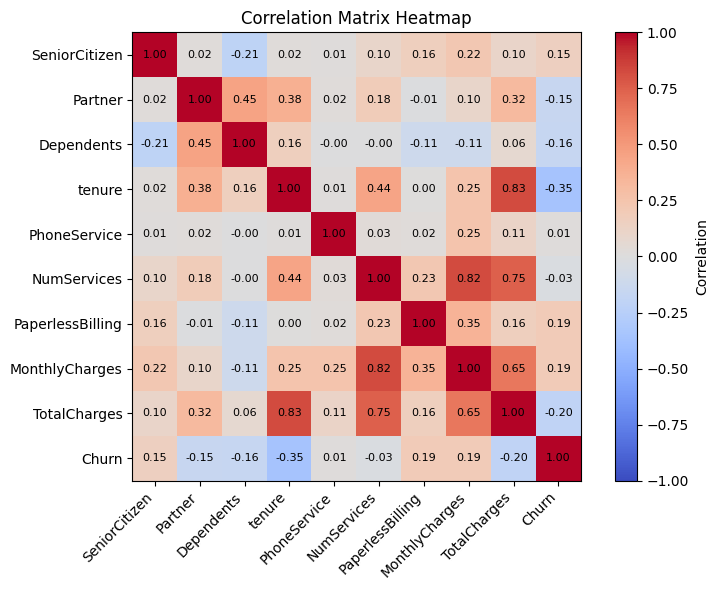

In [11]:
# Correlation matrix for numeric variables in df_raw
correlation_matrix = df_raw.select_dtypes(include=[np.number]).corr()

# Heatmap using matplotlib
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))
ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha='right')
ax.set_yticklabels(correlation_matrix.columns)

for row in range(len(correlation_matrix)):
    for col in range(len(correlation_matrix.columns)):
        ax.text(col, row, f"{correlation_matrix.iloc[row, col]:.2f}",
                ha='center', va='center', color='black', fontsize=8)

fig.colorbar(cax, ax=ax, label='Correlation')
ax.set_title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

In [12]:
# Encoding other variables for visualization
gender_dict = {'Female':0,'Male':1}

internet_dict = {'No': 0, 'DSL': 1, 'Fiber optic': 2} 
multiple_lines_dict = {'No phone service': 0, 'No': 1, 'Yes': 2}
services_dict= {'No internet service': 0, 'No': 1, 'Yes': 2}
payment_dict = {'Electronic check': 0,'Mailed check': 1,'Bank transfer (automatic)': 2, 'Credit card (automatic)': 3}
contract_dict = {'Month-to-month': 0, 'One year': 1, 'Two year': 2}


df = df_raw.copy()

df['gender'] = df['gender'].replace(gender_dict).astype(int)
df['MultipleLines'] = df['MultipleLines'].replace(multiple_lines_dict).astype(int)
df['InternetService'] = df['InternetService'].replace(internet_dict).astype(int)
df['OnlineSecurity'] = df['OnlineSecurity'].replace(services_dict).astype(int)
df['OnlineBackup'] = df['OnlineBackup'].replace(services_dict).astype(int)
df['DeviceProtection'] = df['DeviceProtection'].replace(services_dict).astype(int)
df['TechSupport'] = df['TechSupport'].replace(services_dict).astype(int)
df['StreamingTV'] = df['StreamingTV'].replace(services_dict).astype(int)
df['StreamingMovies'] = df['StreamingMovies'].replace(services_dict).astype(int)
df['Contract'] = df['Contract'].replace(contract_dict).astype(int)
df['PaymentMethod'] = df['PaymentMethod'].replace(payment_dict).astype(int)


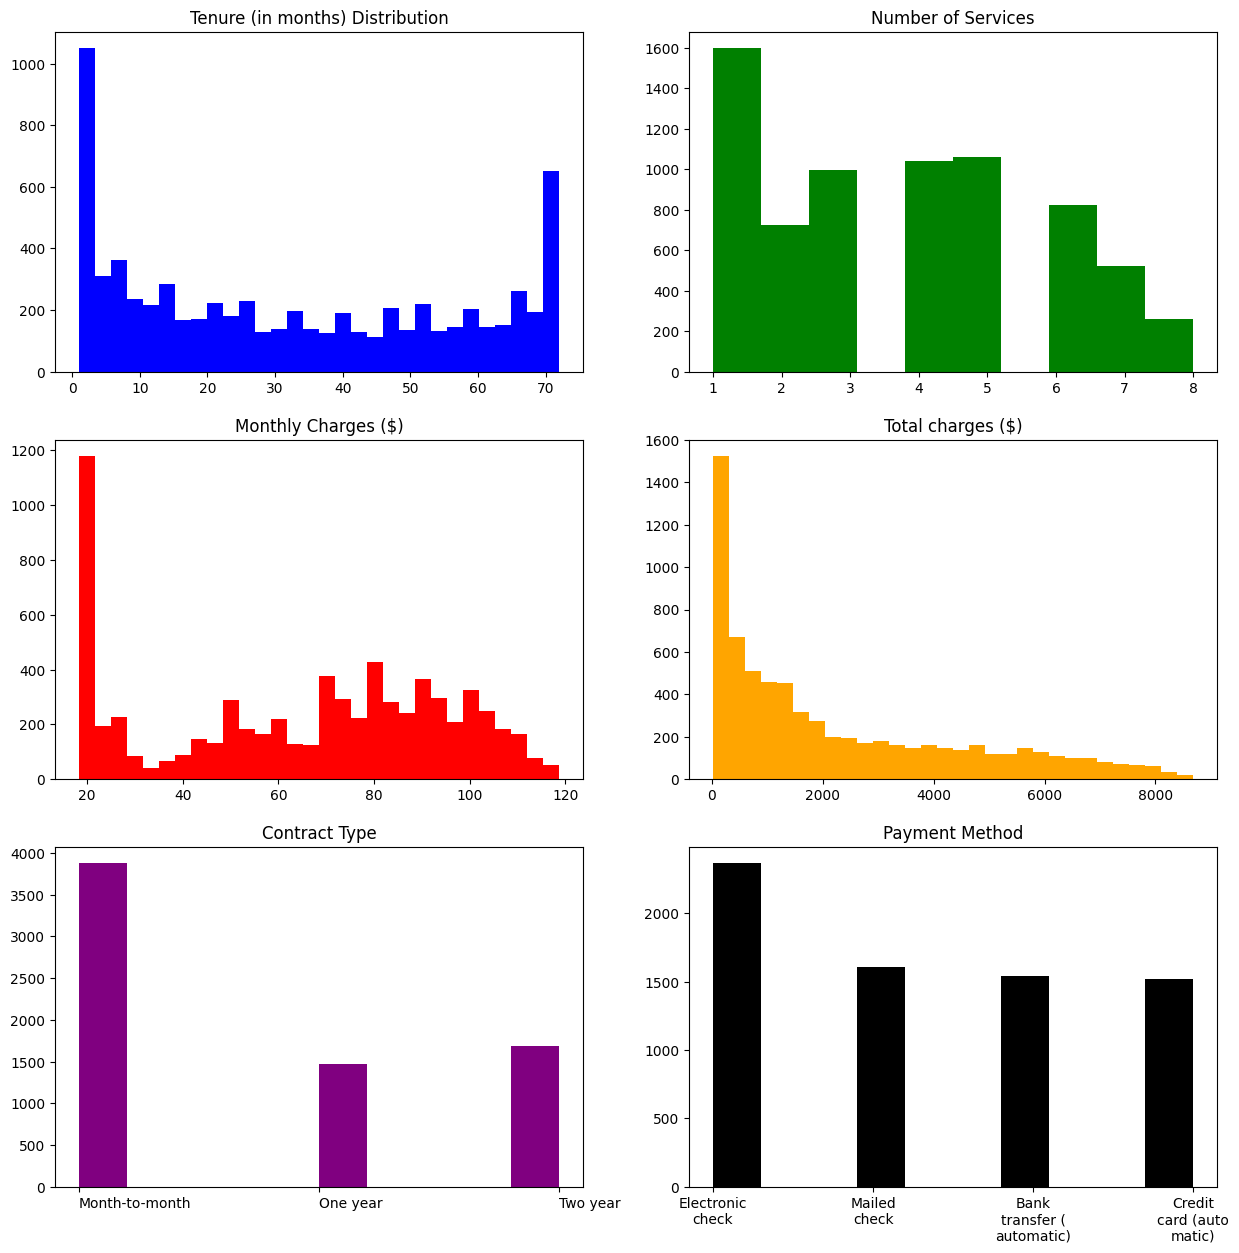

In [13]:
# General Distribution
fig, axs = plt.subplots(3,2)
fig.set_figheight(15)
fig.set_figwidth(15)

axs[0,0].hist(df['tenure'],bins=30,color='blue')
axs[0,0].title.set_text('Tenure (in months) Distribution')

axs[0,1].hist(df['NumServices'],bins=10,color='green')
axs[0,1].title.set_text('Number of Services')

axs[1,0].hist(df['MonthlyCharges'],bins=30,color='red')
axs[1,0].title.set_text('Monthly Charges ($)')

axs[1,1].hist(df['TotalCharges'],bins=30,color='orange')
axs[1,1].title.set_text('Total charges ($)')

axs[2,0].hist(df['Contract'],color='purple')
axs[2,0].set_xticks(list(contract_dict.values()))
axs[2,0].set_xticklabels(list(contract_dict.keys()),ha='left')
axs[2,0].title.set_text('Contract Type')

axs[2,1].hist(df['PaymentMethod'],color='black')
axs[2,1].set_xticks(list(payment_dict.values()))
wrapped_labels = [textwrap.fill(str(key), width=10) for key in payment_dict.keys()]
axs[2,1].set_xticklabels(wrapped_labels)
axs[2,1].title.set_text('Payment Method')

In [14]:
# Creating tenure buckets for easier analysis
def create_tenure_buckets(tenure):
    if tenure <= 3:
        return '0-3 months'
    elif tenure <= 6:
        return '4-6 months'
    elif tenure <= 12:
        return '7-12 months'
    elif tenure <= 24:
        return '13-24 months'
    elif tenure <= 48:
        return '25-48 months'
    else:
        return '49+ months'

df['tenure_bucket'] = df['tenure'].apply(create_tenure_buckets)

In [15]:
# Making two separate dataframes for churned vs stayed customers to compare them

df_churn = df[df['Churn']==1]
df_stay = df[df['Churn']==0]

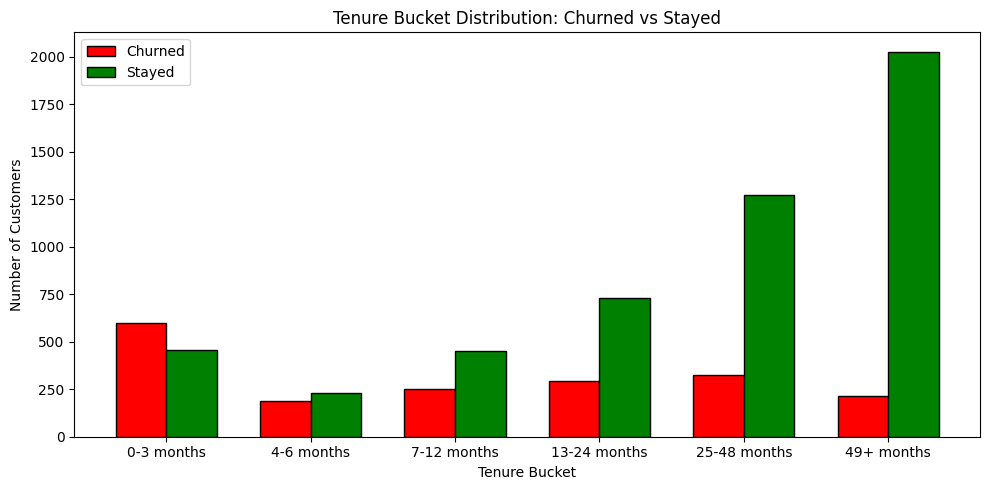

In [16]:
plt.figure(figsize=(10, 5))

# Grouped bar chart comparison 
tenure_buckets = ['0-3 months', '4-6 months', '7-12 months', '13-24 months', '25-48 months', '49+ months']
churn_counts = df_churn['tenure_bucket'].value_counts().reindex(tenure_buckets, fill_value=0)
stay_counts = df_stay['tenure_bucket'].value_counts().reindex(tenure_buckets, fill_value=0)

x = np.arange(len(tenure_buckets))
width = 0.35

plt.bar(x - width/2, churn_counts, width, label='Churned', color='red', edgecolor='black')
plt.bar(x + width/2, stay_counts, width, label='Stayed', color='green', edgecolor='black')
plt.xlabel('Tenure Bucket')
plt.ylabel('Number of Customers')
plt.title('Tenure Bucket Distribution: Churned vs Stayed')
plt.xticks(x, tenure_buckets)
plt.legend()

plt.tight_layout()
plt.show()

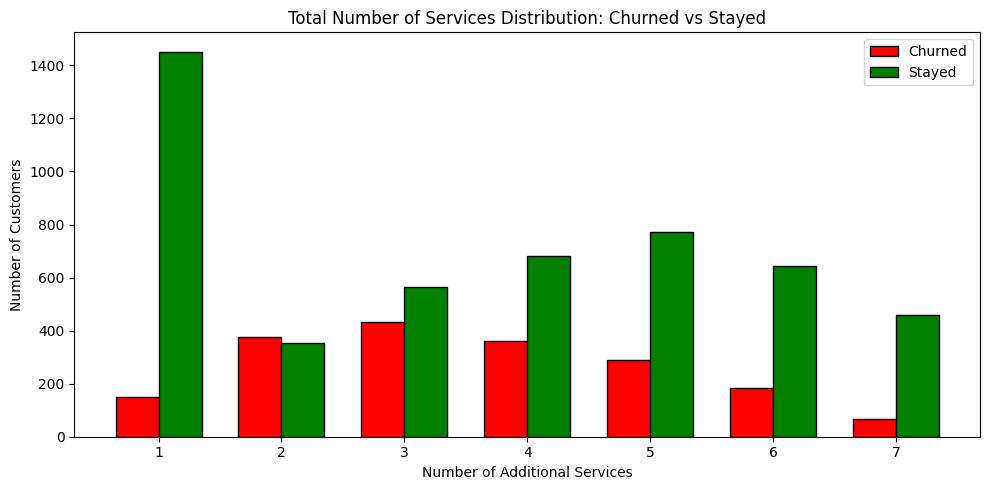

In [17]:
# Compare Number of services distribution: Churned vs Stayed
plt.figure(figsize=(10, 5))

# Grouped bar chart comparison 
addon_values = range(1, 8)
churn_counts = df_churn['NumServices'].value_counts().reindex(addon_values, fill_value=0)
stay_counts = df_stay['NumServices'].value_counts().reindex(addon_values, fill_value=0)

x = np.arange(len(addon_values))
width = 0.35

plt.bar(x - width/2, churn_counts, width, label='Churned', color='red', edgecolor='black')
plt.bar(x + width/2, stay_counts, width, label='Stayed', color='green', edgecolor='black')
plt.xlabel('Number of Additional Services')
plt.ylabel('Number of Customers')
plt.title('Total Number of Services Distribution: Churned vs Stayed')
plt.xticks(x, addon_values)
plt.legend()

plt.tight_layout()
plt.show()

Correlation with Churn (sorted by absolute value):
InternetService     0.316350
StreamingTV         0.164509
StreamingMovies     0.162672
DeviceProtection    0.084402
OnlineBackup        0.073934
MultipleLines       0.036148
TechSupport         0.026744
OnlineSecurity      0.023014
Name: Churn, dtype: float64


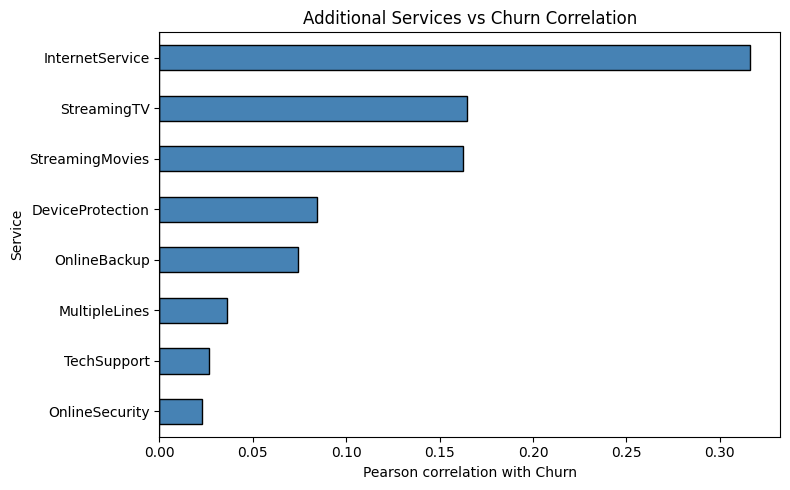


Most correlated service: InternetService (0.316)


In [18]:
# Correlation between additional services and churn
service_cols = [
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

service_corr = df[service_cols + ['Churn']].corr(numeric_only=True)['Churn'].drop('Churn')
service_corr = service_corr.sort_values(key=lambda s: s.abs(), ascending=False)

print("Correlation with Churn (sorted by absolute value):")
print(service_corr)

plt.figure(figsize=(8, 5))
service_corr.sort_values().plot(kind='barh', color='steelblue', edgecolor='black')
plt.axvline(0, color='black', linewidth=1)
plt.title('Additional Services vs Churn Correlation')
plt.xlabel('Pearson correlation with Churn')
plt.ylabel('Service')
plt.tight_layout()
plt.show()

print(f"\nMost correlated service: {service_corr.abs().idxmax()} ({service_corr.abs().max():.3f})")

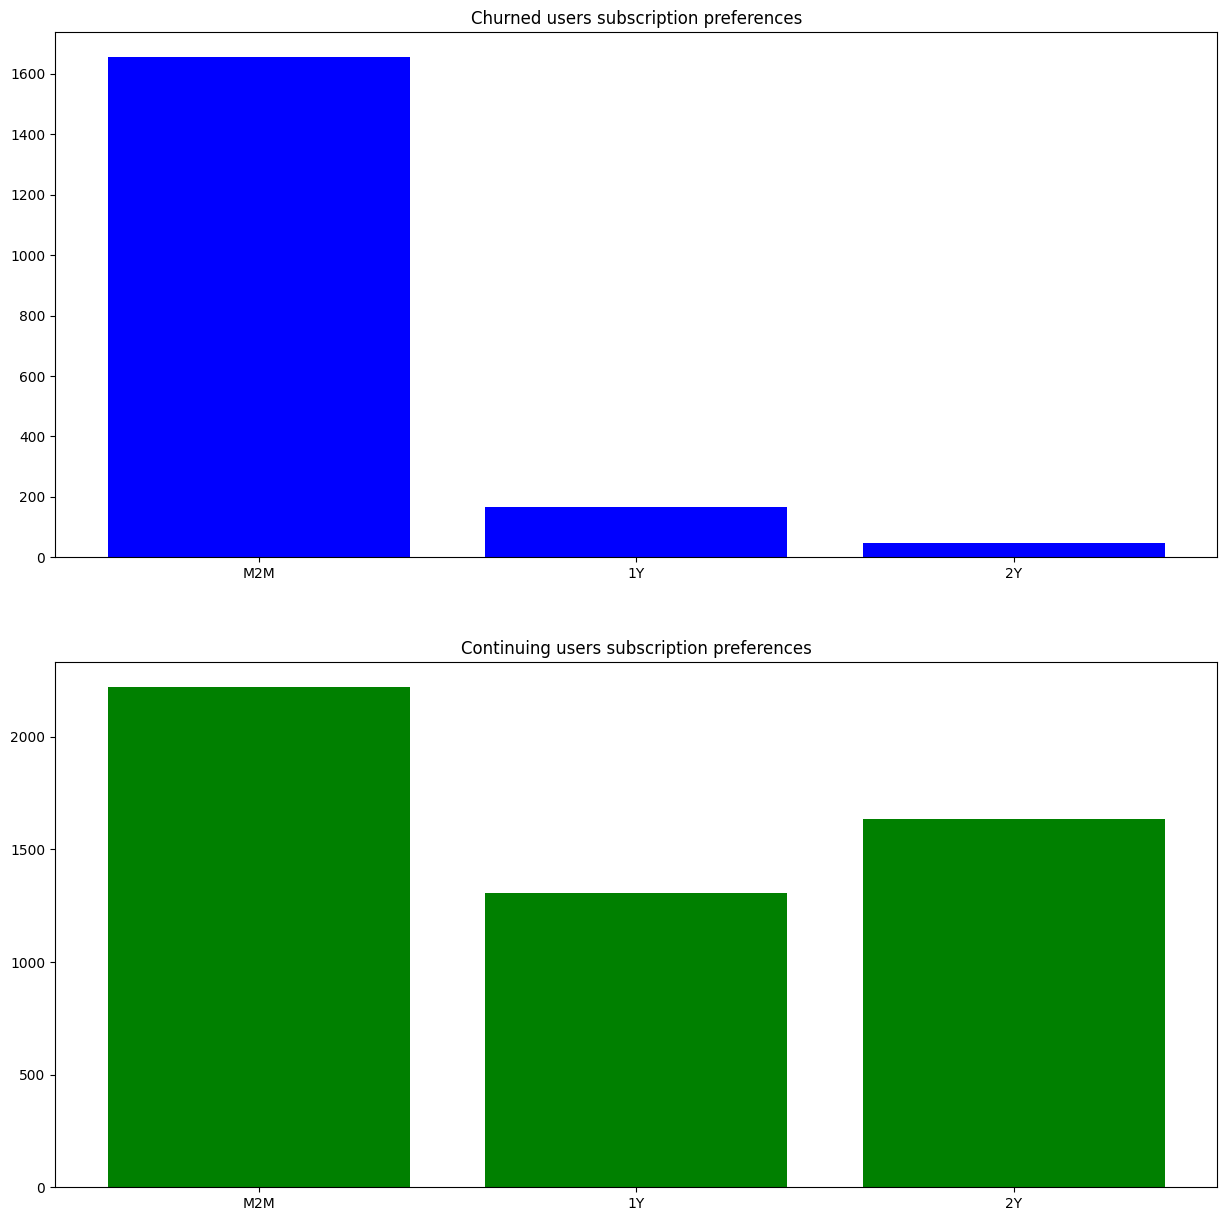

In [19]:
# Churn vs. Contract Type
fig,axs = plt.subplots(2,1)
contract_types = ['Month-to-Month','One Year','Two Year']
churn_counts = df_churn['Contract'].value_counts().reindex([0,1,2], fill_value=0)
stay_counts = df_stay['Contract'].value_counts().reindex([0,1,2], fill_value=0)
fig.set_figheight(15)
fig.set_figwidth(15)
axs[0].bar(['M2M','1Y','2Y'], churn_counts,color='blue')
axs[0].title.set_text('Churned users subscription preferences')
axs[1].bar(['M2M','1Y','2Y'], stay_counts,color='green')
axs[1].title.set_text('Continuing users subscription preferences')

/var/folders/c8/nthc9f493jv664g291zn4_qc0000gn/T/ipykernel_19932/2774208281.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp1 = axs[0].boxplot(churn_data, patch_artist=True, labels=tenure_buckets)
/var/folders/c8/nthc9f493jv664g291zn4_qc0000gn/T/ipykernel_19932/2774208281.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = axs[1].boxplot(stay_data, patch_artist=True, labels=tenure_buckets)


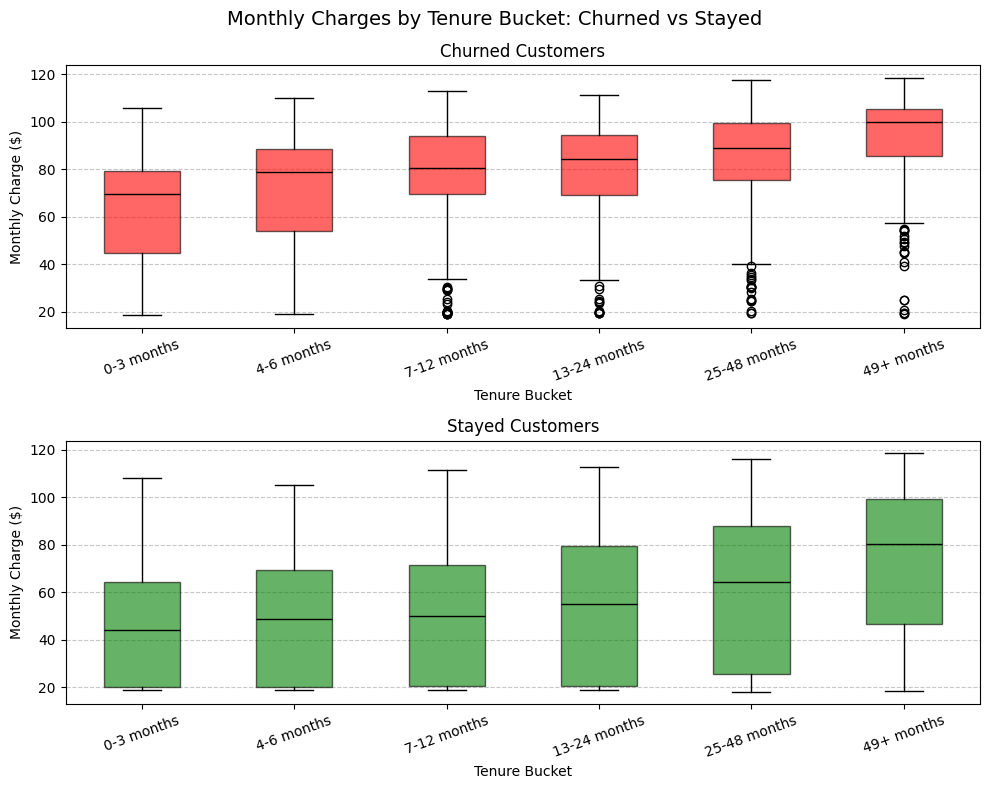

In [20]:
# Tenure Bucket vs Avg Charges per month - Box Plot
fig, axs = plt.subplots(2,1, figsize=(10, 8),sharey=True)

# Churned customers box plot
churn_data = [df_churn[df_churn['tenure_bucket'] == bucket]['MonthlyCharges'].dropna() for bucket in tenure_buckets]
bp1 = axs[0].boxplot(churn_data, patch_artist=True, labels=tenure_buckets)
for patch,median in zip(bp1['boxes'],bp1['medians']):
    patch.set_facecolor('red')
    patch.set_alpha(0.6)
    median.set_color('black')
    
axs[0].set_xlabel('Tenure Bucket')
axs[0].set_ylabel('Monthly Charge ($)')
axs[0].set_title('Churned Customers')
axs[0].tick_params(axis='x', rotation=20)
axs[0].grid(axis='y', linestyle='--', alpha=0.7)

# Stayed customers box plot
stay_data = [df_stay[df_stay['tenure_bucket'] == bucket]['MonthlyCharges'].dropna() for bucket in tenure_buckets]
bp2 = axs[1].boxplot(stay_data, patch_artist=True, labels=tenure_buckets)
for patch,median in zip(bp2['boxes'],bp2['medians']):
    patch.set_facecolor('green')
    patch.set_alpha(0.6)
    median.set_color('black')
axs[1].set_xlabel('Tenure Bucket')
axs[1].set_ylabel('Monthly Charge ($)')
axs[1].set_title('Stayed Customers')
axs[1].tick_params(axis='x', rotation=20)
axs[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle('Monthly Charges by Tenure Bucket: Churned vs Stayed', fontsize=14)
plt.tight_layout()
plt.show()

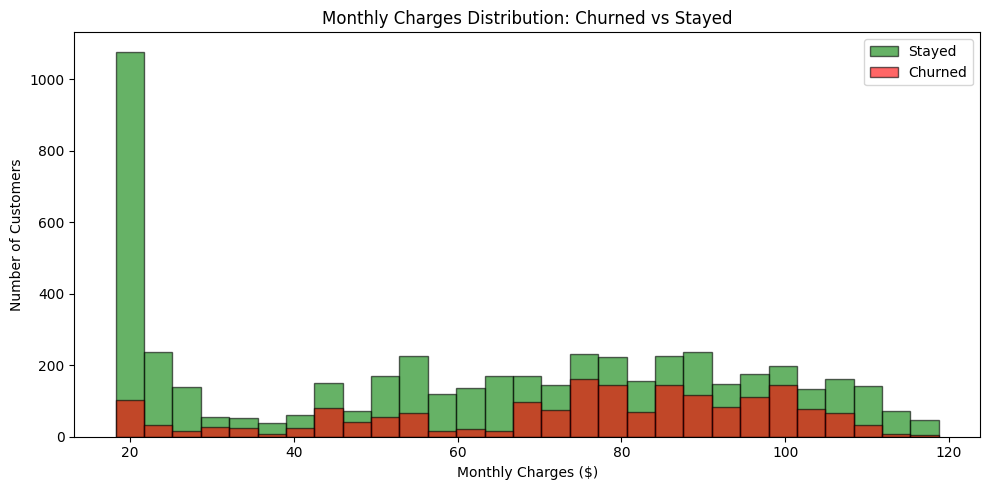

In [21]:
# MonthlyCharges distribution: Churned vs Stayed
plt.figure(figsize=(10, 5))

bins = np.linspace(df['MonthlyCharges'].min(), df['MonthlyCharges'].max(), 30)
plt.hist(df_stay['MonthlyCharges'], bins=bins, alpha=0.6, label='Stayed', color='green', edgecolor='black')
plt.hist(df_churn['MonthlyCharges'], bins=bins, alpha=0.6, label='Churned', color='red', edgecolor='black')

plt.xlabel('Monthly Charges ($)')
plt.ylabel('Number of Customers')
plt.title('Monthly Charges Distribution: Churned vs Stayed')
plt.legend()
plt.tight_layout()
plt.show()

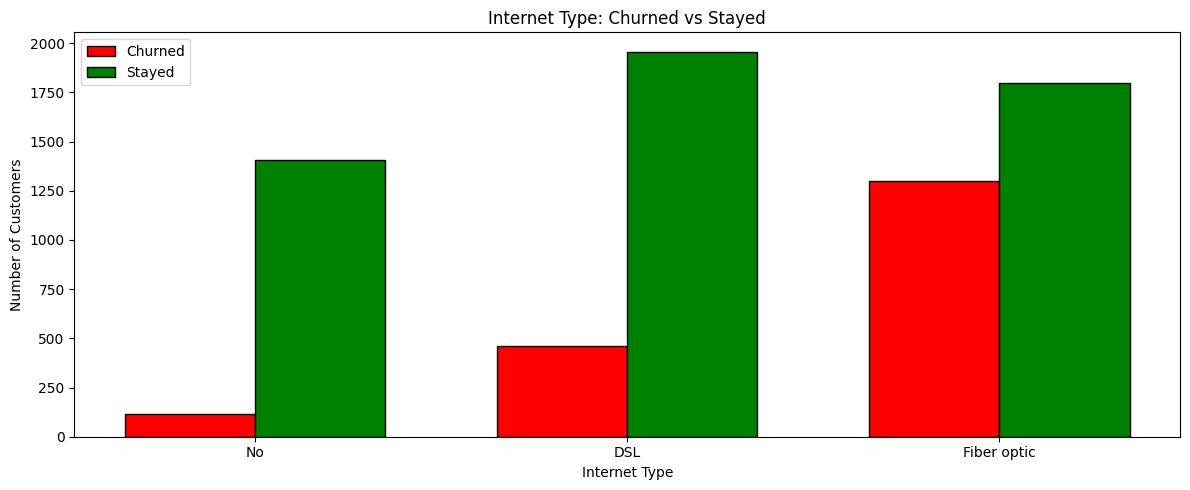

In [22]:
# Internet_type vs no.of customers - Churned vs Stayed
churn_counts = df_churn['InternetService'].value_counts().reindex([0,1,2], fill_value=0)
stay_counts = df_stay['InternetService'].value_counts().reindex([0,1,2], fill_value=0)

x = np.arange(len(churn_counts))
width = 0.35

plt.figure(figsize=(12, 5))
plt.bar(x - width/2, churn_counts, width, label='Churned', color='red', edgecolor='black')
plt.bar(x + width/2, stay_counts, width, label='Stayed', color='green', edgecolor='black')
plt.xlabel('Internet Type')
plt.ylabel('Number of Customers')
plt.title('Internet Type: Churned vs Stayed')
plt.xticks(x, internet_dict.keys())
plt.legend()
plt.tight_layout()
plt.show()

<h2>Principal Component Analysis</h2>

In [23]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'NumServices', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'tenure_bucket'],
      dtype='str')

In [24]:
# Collapsing service columns to be binary
df_model = df.copy()

# MultipleLines was encoded {'No phone service':0, 'No':1, 'Yes':2}
# Collapse 0 and 1 into "No" (0), keep 2 as "Yes" (1)
df_model['MultipleLines'] = df_model['MultipleLines'].replace({0: 0, 1: 0, 2: 1})

# service_dict fields were encoded {'No internet service':0, 'No':1, 'Yes':2}
# Same collapse: 0 and 1 -> "No" (0), 2 -> "Yes" (1)
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in service_cols:
    df_model[col] = df_model[col].replace({0: 0, 1: 0, 2: 1})

# InternetService was encoded {'No':0, 'DSL':1, 'Fiber optic':2} - ordinal, needs to be one-hot instead
df_model['Internet_DSL'] = (df_model['InternetService'] == 1).astype(int)
df_model['Internet_Fiber'] = (df_model['InternetService'] == 2).astype(int)
df_model['Internet_No'] = (df_model['InternetService'] == 0).astype(int)
df_model = df_model.drop(columns=['InternetService'])

# sanity check - each collapsed column should now only contain {0, 1}
print(df_model[['MultipleLines'] + service_cols].apply(pd.Series.unique))

   MultipleLines  OnlineSecurity  OnlineBackup  DeviceProtection  TechSupport  \
0              0               0             1                 0            0   
1              1               1             0                 1            1   

   StreamingTV  StreamingMovies  
0            0                0  
1            1                1  


In [25]:
pca_features = ['tenure', 'MonthlyCharges', 'NumServices',
                 'PhoneService', 'MultipleLines',
                 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies',
                 'Internet_DSL', 'Internet_Fiber','Internet_No']

df_pca = df_model[pca_features].copy()

Number of components explaining 60% of the variance: 3


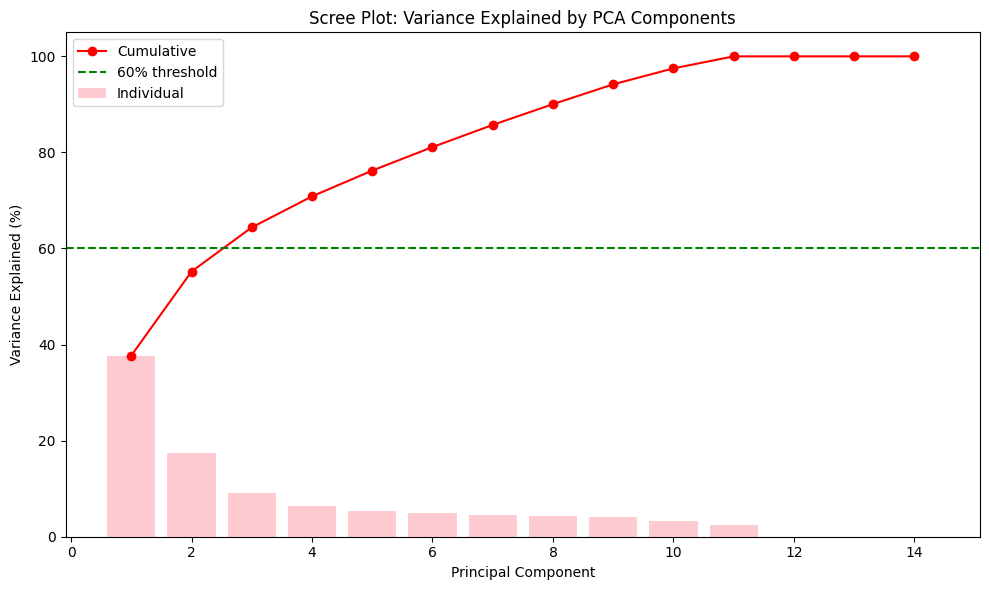

In [26]:

# Standardize the features
scaler = StandardScaler()
pca_scaled = scaler.fit_transform(df_pca)

# Fit PCA
pca = PCA()
pca.fit(pca_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Number of components to explain 60% of the variance
n_components_60 = np.argmax(cumulative_variance >= 0.60) + 1
print(f"Number of components explaining 60% of the variance: {n_components_60}")

# Scree plot
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance * 100, alpha=0.7, label='Individual', color='lightpink')
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance * 100, marker='o', color='red', label='Cumulative')
plt.axhline(60, color='green', linestyle='--', label='60% threshold')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained (%)')
plt.title('Scree Plot: Variance Explained by PCA Components')
plt.legend()
plt.tight_layout()
plt.show()

We have two dominant components worth naming and interpreting (PC1, PC2 together cover just over half the variance), and the rest is comparatively nominal as no single later component stands out as a distinct "third story." That's a reasonable, expected result given how many binary service-flag columns are in the input (each one only contributes a little on its own).

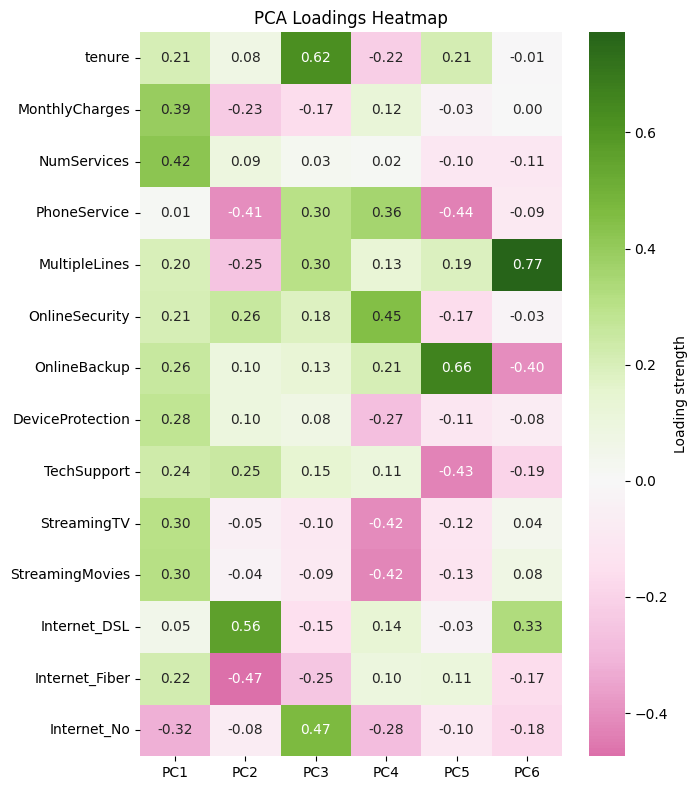

In [27]:
import seaborn as sns


# Loadings for the top few components (adjust n_components as needed)
n_components = 6
loadings = pd.DataFrame(
    pca.components_[:n_components].T,
    columns=[f'PC{i+1}' for i in range(n_components)],
    index=df_pca.columns
)

plt.figure(figsize=(7, 8))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='PiYG', center=0,
             cbar_kws={'label': 'Loading strength'})
plt.title('PCA Loadings Heatmap')
plt.tight_layout()
plt.show()

In [32]:
# plt.figure(figsize=(8, 6))
# plt.scatter(loadings[:, 0], loadings[:, 1], s=12, alpha=0.5, color='steelblue', edgecolors='none')

# plt.xlabel(f'PC1 ({explained_variance[0] * 100:.1f}% variance)')
# plt.ylabel(f'PC2 ({explained_variance[1] * 100:.1f}% variance)')
# plt.title('PCA Projection of df_pca on PC1 and PC2')
# plt.grid(True, linestyle='--', alpha=0.3)
# plt.tight_layout()
# plt.show()

<h2>K-Means Clustering</h2>

In [33]:
df_model.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'NumServices', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'tenure_bucket', 'Internet_DSL', 'Internet_Fiber', 'Internet_No'],
      dtype='str')

In [34]:
feature_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'NumServices', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'Internet_DSL', 
       'Internet_Fiber', 'Internet_No']

X_cluster = df_model[feature_cols].copy()

# Scale features (important for K-Means)
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

print("Scaled data shape:", X_cluster_scaled.shape)
print("\nScaled data stats:")
print(pd.DataFrame(X_cluster_scaled, columns=feature_cols).describe())

Scaled data shape: (7032, 21)

Scaled data stats:
             gender  SeniorCitizen       Partner    Dependents        tenure  \
count  7.032000e+03   7.032000e+03  7.032000e+03  7.032000e+03  7.032000e+03   
mean  -7.679358e-17   2.627149e-17  6.264740e-17  6.466828e-17 -1.126643e-16   
std    1.000071e+00   1.000071e+00  1.000071e+00  1.000071e+00  1.000071e+00   
min   -1.009430e+00  -4.403271e-01 -9.656081e-01 -6.523049e-01 -1.280248e+00   
25%   -1.009430e+00  -4.403271e-01 -9.656081e-01 -6.523049e-01 -9.542963e-01   
50%    9.906580e-01  -4.403271e-01 -9.656081e-01 -6.523049e-01 -1.394171e-01   
75%    9.906580e-01  -4.403271e-01  1.035617e+00  1.533025e+00  9.199259e-01   
max    9.906580e-01   2.271039e+00  1.035617e+00  1.533025e+00  1.612573e+00   

       PhoneService  MultipleLines  OnlineSecurity  OnlineBackup  \
count  7.032000e+03   7.032000e+03    7.032000e+03  7.032000e+03   
mean   1.374201e-16   3.637591e-17   -1.503032e-17 -4.408053e-17   
std    1.000071e+00   1.0

<h3>Selecting optimal k</h3>

k=2: Silhouette Score = 0.176, Inertia = 119792.93
k=3: Silhouette Score = 0.168, Inertia = 104941.18
k=4: Silhouette Score = 0.192, Inertia = 93536.80
k=5: Silhouette Score = 0.184, Inertia = 87814.53
k=6: Silhouette Score = 0.181, Inertia = 83434.11
k=7: Silhouette Score = 0.178, Inertia = 80270.15
k=8: Silhouette Score = 0.142, Inertia = 77478.64


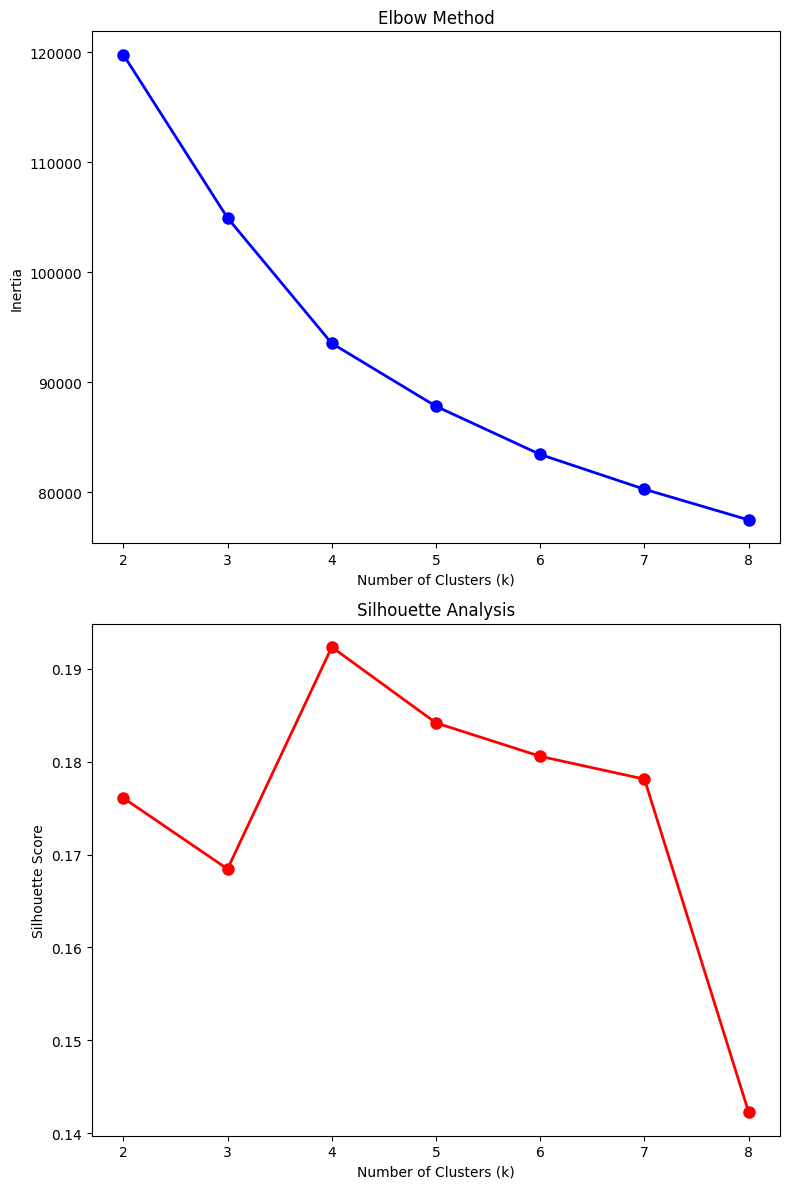

In [35]:
k_values = [2, 3, 4, 5, 6, 7, 8]
sil_scores = []
inertias = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_cluster_scaled)

    # Silhouette score
    score = silhouette_score(X_cluster_scaled, labels)
    sil_scores.append(score)

    # Inertia for elbow method
    inertias.append(kmeans.inertia_)

    print(f"k={k}: Silhouette Score = {score:.3f}, Inertia = {kmeans.inertia_:.2f}")

# Combined dataframe
scores_df = pd.DataFrame({
    "k": k_values,
    "silhouette_score": sil_scores,
    "inertia": inertias
})

# Visualization
fig, axes = plt.subplots(2,1, figsize=(8, 12))

# Elbow plot
axes[0].plot(k_values, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')

# Silhouette plot
axes[1].plot(k_values, sil_scores, 'ro-', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Analysis')

plt.tight_layout()
plt.show()

<h3> Final Fit Clustering Model </h3>
<h5> Based on the scores, we'll choose k = 4, to create distinct user personas </h5>

In [36]:
k_opt = 4
kmeans_opt = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
cluster_labels = kmeans_opt.fit_predict(X_cluster_scaled)

df_model["cluster"] = cluster_labels

print("Cluster distribution:")
print(df_model["cluster"].value_counts().sort_index())

Cluster distribution:
cluster
0    1675
1    1682
2    2153
3    1522
Name: count, dtype: int64


<h3>PCA Visualization of Clusters</h3>

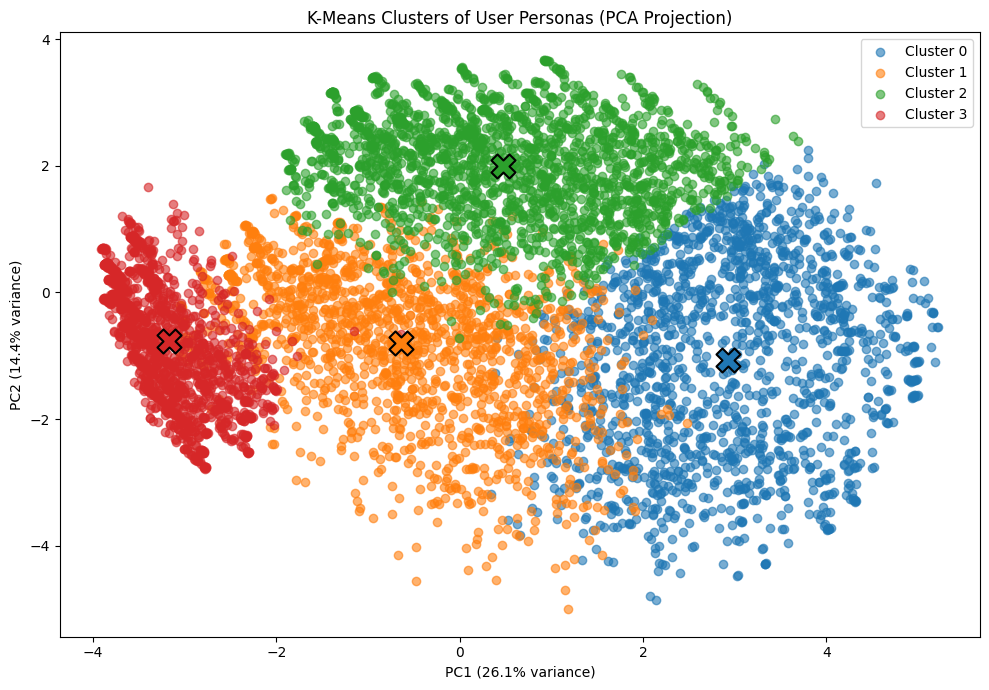

In [37]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster_scaled)

centroids_pca = pca.transform(kmeans_opt.cluster_centers_)

plt.figure(figsize=(10, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c','#d62728', '#9467bd']  
for cluster_id in range(k_opt):
    mask = cluster_labels == cluster_id
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.6,
        c=colors[cluster_id]
    )

# Plot centroids on top - larger marker, black edge so they stand out from the points
for cluster_id in range(k_opt):
    plt.scatter(
        centroids_pca[cluster_id, 0],
        centroids_pca[cluster_id, 1],
        c=colors[cluster_id],
        marker='X',
        s=300,
        edgecolors='black',
        linewidths=1.5,
        zorder=5
    )

plt.title("K-Means Clusters of User Personas (PCA Projection)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
# Interpretable cluster profiles
print("TELCO CUSTOMER PERSONAS")
print("=" * 60)

contract_labels = {0: 'Month-to-month', 1: 'One year', 2: 'Two year'}
total_customers = len(df_model)

for cluster_id in range(k_opt):
    cluster_data = df_model[df_model["cluster"] == cluster_id]
    n_customers = len(cluster_data)
    pct_of_total = (n_customers / total_customers) * 100
    pct_churn = cluster_data["Churn"].mean() * 100

    print(f"\nCLUSTER {cluster_id}: {n_customers} customers ({pct_of_total:.1f}% of all customers, {pct_churn:.1f}% churn rate)")
    print("-" * 40)

    # Tenure summary
    avg_tenure = cluster_data["tenure"].mean()
    overall_tenure = df_model["tenure"].mean()
    tenure_diff = ((avg_tenure - overall_tenure) / overall_tenure) * 100
    tenure_dir = "↑" if tenure_diff > 10 else ("↓" if tenure_diff < -10 else "~")
    print(f"  {'tenure':30s}: {avg_tenure:.1f} months ({tenure_dir} {abs(tenure_diff):.0f}% vs avg)")

    # Full Contract type breakdown
    contract_pct = (cluster_data["Contract"].value_counts(normalize=True) * 100).sort_index()
    print(f"  {'Contract breakdown':30s}:")
    for code, pct in contract_pct.items():
        print(f"      {contract_labels[code]:20s}: {pct:.1f}%")

    # Show key characteristics for the variables actually used in clustering
    for feat in feature_cols:
        if feat == "Contract":
            continue

        val = cluster_data[feat].mean()
        overall_mean = df_model[feat].mean()
        if overall_mean != 0:
            diff = ((val - overall_mean) / overall_mean) * 100
        else:
            diff = 0
        direction = "↑" if diff > 10 else ("↓" if diff < -10 else "~")

        if feat.startswith(('Internet_',)) or feat in [
            'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
            'PaperlessBilling'
        ]:
            print(f"  {feat:30s}: {val:.2f} ({direction} {abs(diff):.0f}% vs avg)")
        else:
            print(f"  {feat:30s}: {val:.2f} ({direction} {abs(diff):.0f}% vs avg)")

TELCO CUSTOMER PERSONAS

CLUSTER 0: 1675 customers (23.8% of all customers, 11.0% churn rate)
----------------------------------------
  tenure                        : 58.1 months (↑ 79% vs avg)
  Contract breakdown            :
      Month-to-month      : 11.7%
      One year            : 34.7%
      Two year            : 53.6%
  gender                        : 0.49 (~ 2% vs avg)
  SeniorCitizen                 : 0.15 (~ 7% vs avg)
  Partner                       : 0.74 (↑ 53% vs avg)
  Dependents                    : 0.41 (↑ 37% vs avg)
  tenure                        : 58.08 (↑ 79% vs avg)
  PhoneService                  : 0.95 (~ 6% vs avg)
  MultipleLines                 : 0.71 (↑ 68% vs avg)
  OnlineSecurity                : 0.65 (↑ 126% vs avg)
  OnlineBackup                  : 0.73 (↑ 111% vs avg)
  DeviceProtection              : 0.79 (↑ 129% vs avg)
  TechSupport                   : 0.71 (↑ 145% vs avg)
  StreamingTV                   : 0.79 (↑ 105% vs avg)
  StreamingMovies

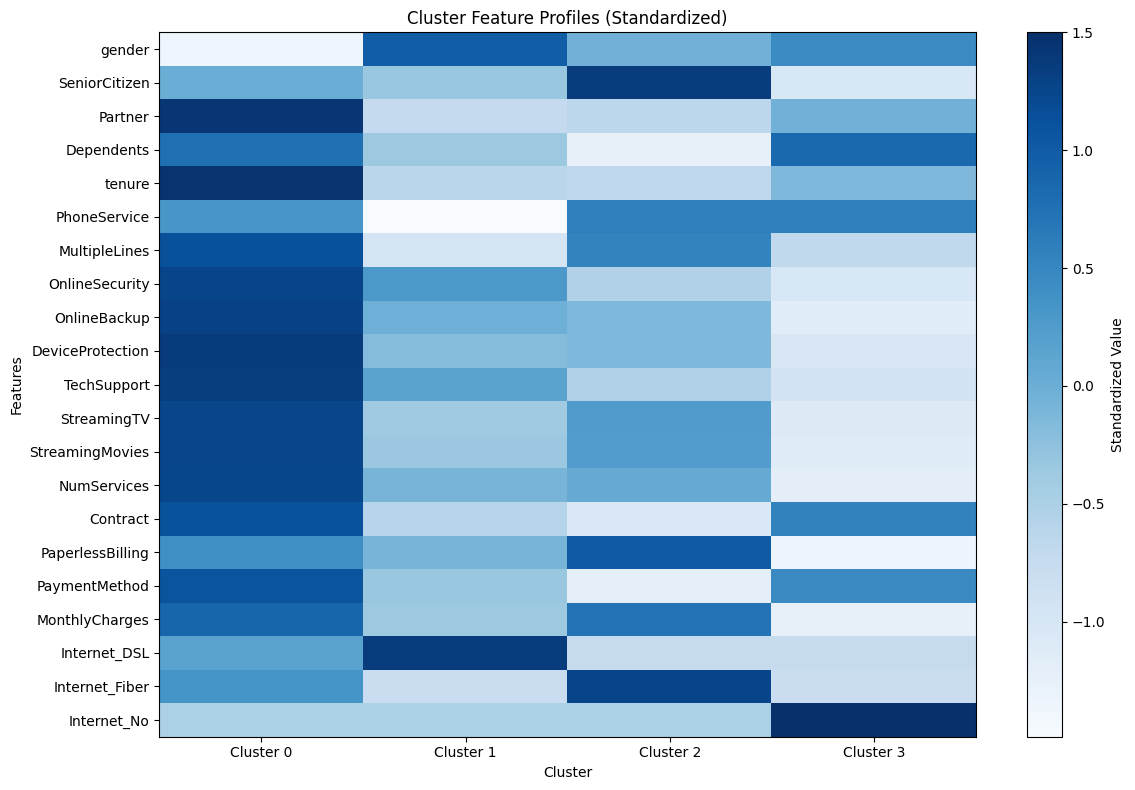

In [39]:
# Normalized heatmap of cluster characteristics

cluster_means = df_model.groupby('cluster')[feature_cols].mean()
cluster_normalized = (cluster_means - cluster_means.mean()) / cluster_means.std()

cluster_data = cluster_normalized.values.astype(float).T 

# Create heatmap
plt.figure(figsize=(12, 8))
plt.imshow(cluster_data, cmap='Blues', aspect='auto')
plt.colorbar(label='Standardized Value')
plt.xticks(range(len(cluster_normalized)), [f'Cluster {i}' for i in cluster_normalized.index])
plt.yticks(range(len(feature_cols)), feature_cols)
plt.xlabel('Cluster')
plt.ylabel('Features')
plt.title('Cluster Feature Profiles (Standardized)')
plt.tight_layout()
plt.show()

In [40]:
df_model.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,NumServices,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_bucket,Internet_DSL,Internet_Fiber,Internet_No,cluster
0,7590-VHVEG,0,0,1,0,1,0,0,0,1,0,0,0,0,2,0,1,0,29.85,29.85,0,0-3 months,1,0,0,1
1,5575-GNVDE,1,0,0,0,34,1,0,1,0,1,0,0,0,4,1,0,1,56.95,1889.50,0,25-48 months,1,0,0,1
2,3668-QPYBK,1,0,0,0,2,1,0,1,1,0,0,0,0,4,0,1,1,53.85,108.15,1,0-3 months,1,0,0,1
3,7795-CFOCW,1,0,0,0,45,0,0,1,0,1,1,0,0,4,1,0,2,42.30,1840.75,0,25-48 months,1,0,0,1
4,9237-HQITU,0,0,0,0,2,1,0,0,0,0,0,0,0,2,0,1,0,70.70,151.65,1,0-3 months,0,1,0,2
5,9305-CDSKC,0,0,0,0,8,1,1,0,0,1,0,1,1,5,0,1,0,99.65,820.50,1,7-12 months,0,1,0,2
6,1452-KIOVK,1,0,0,1,22,1,1,0,1,0,0,1,0,4,0,1,3,89.10,1949.40,0,13-24 months,0,1,0,2
7,6713-OKOMC,0,0,0,0,10,0,0,1,0,0,0,0,0,2,0,0,1,29.75,301.90,0,7-12 months,1,0,0,1
8,7892-POOKP,0,0,1,0,28,1,1,0,0,1,1,1,1,6,0,1,0,104.80,3046.05,1,25-48 months,0,1,0,2
9,6388-TABGU,1,0,0,1,62,1,0,1,1,0,0,0,0,4,1,0,2,56.15,3487.95,0,49+ months,1,0,0,1


In [42]:
pd.DataFrame(df_model).to_csv('df_model.csv', index=False)